# 30 Doradus Hα distributions: MUSE, SAMFP, and FLAMES

MUSE/SAMFP use masked moment images. FLAMES uses the **selected FITS table** exported by `list_01_fits_create_H-6563`, preserving its spatial and velocity selections. No gridding or new Gaussian fitting is required.

Set paths in the next cell, then run all cells. The three input FITS files must exist locally. An explicit JSON option is provided for inspecting the earlier FLAMES product, but it does not reproduce the FITS export's spatial selection automatically.

Each pixel or table row has equal weight; these are sampled distributions, not a matched-footprint or area-weighted comparison. Multiple components or repeat observations, if present in the export, remain separate rows.

**Measurement conventions:** `log_F` is assumed to be base-10 logarithmic brightness. Its physical units and whether it is integrated line flux or peak amplitude are not specified by the supplied export. Confirm these upstream before interpreting it as equivalent to MOM0. Median normalization removes a constant scale factor, not differences in the measured quantity. FLAMES `V_mean` is used as exported; no systemic-velocity offset is guessed. The plotted velocity is centered separately for each dataset. Line widths are retained but not plotted as centroid dispersions.


In [18]:
from pathlib import Path

import json

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

# --------------------------------------------------
# Paths
# --------------------------------------------------
ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_files"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)

FLAMES_PATH = ROOT / "fits_files" / "FLAMES-30Dor-6563-complete.fits"
FLAMES_FORMAT = "fits_table"

# Alternative: inspect the input JSON instead of the selected FITS table.
# FLAMES_PATH = ROOT / "observations" / "FLAMES-30Dor-6563-l.json"
# FLAMES_FORMAT = "json"
# Applies only to JSON, in its exported velocity convention (strict bounds).
# This reproduces only the velocity cut, NOT the spatial selection.
FLAMES_JSON_VELOCITY_LIMITS = (-45.0, 45.0)  # None keeps every JSON row


In [27]:
# --------------------------------------------------
# Current samples
# --------------------------------------------------

datasets = [
    {
        "instrument": "MUSE",
        "line": "H",
        "filename": "MUSE-30Dor-H-bin0.fits",
        "label": r"H$\alpha$",
    },
    {
        "instrument": "SAMFP",
        "line": "H",
        "filename": "SAMFP-30Dor-Ha-bin0.fits",
        "label": r"H$\alpha$",
    },
]

datasets.append({
    "instrument": "FLAMES", "line": "H", "label": r"H$\alpha$",
    "filename": str(FLAMES_PATH), "format": FLAMES_FORMAT,
})

INSTRUMENT_ORDER = ("MUSE", "SAMFP", "FLAMES")

instrument_colors = {
    "MUSE": "gray",
    "SAMFP": "darkgray",
    "FLAMES": "black",
}


## Load the FITS maps

`MASK=True` is interpreted as a valid pixel, following the convention used in the previous notebook. The mask is applied to all available moments before flattening the maps.


In [28]:
def load_moment_dataset(entry, fits_dir=FITS_DIR):
    from astropy.io import fits

    fits_path = fits_dir / entry["filename"]

    with fits.open(fits_path) as hdul:
        mom0 = hdul["MOM0"].data.astype(float)
        mom1 = hdul["MOM1"].data.astype(float)
        mask = hdul["MASK"].data.astype(bool)

        # MOM2 is expected in the current workflow, but keep the
        # loader tolerant in case an older file does not contain it.
        if "MOM2" in hdul:
            mom2 = hdul["MOM2"].data.astype(float)
        else:
            mom2 = np.full_like(mom1, np.nan, dtype=float)

    # --------------------------------------------------
    # Apply the same mask to every moment
    # --------------------------------------------------
    mom0 = np.where(mask, mom0, np.nan)
    mom1 = np.where(mask, mom1, np.nan)
    mom2 = np.where(mask, mom2, np.nan)

    yy, xx = np.indices(mom1.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "SB": mom0.ravel(),
        "VV": mom1.ravel(),
        "SIGMA": mom2.ravel(),
        "mask": mask.ravel(),
    })

    # Retain only pixels admitted by the FITS mask.
    df = df[df["mask"]].copy()

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]

    # --------------------------------------------------
    # Centered radial velocity
    # --------------------------------------------------
    mean_v = df["VV"].mean(skipna=True)
    df["RV_centered"] = df["VV"] - mean_v

    # --------------------------------------------------
    # Brightness quantities
    # --------------------------------------------------
    # Positive MOM0 values are required for logarithms.
    positive_sb = df["SB"].where(df["SB"] > 0)

    median_sb = positive_sb.median(skipna=True)

    df["log_SB"] = np.log10(positive_sb)

    if np.isfinite(median_sb) and median_sb > 0:
        df["SB_norm"] = positive_sb / median_sb
        df["log_SB_norm"] = np.log10(df["SB_norm"])
    else:
        df["SB_norm"] = np.nan
        df["log_SB_norm"] = np.nan

    raw = {
        "mom0": mom0,
        "mom1": mom1,
        "mom2": mom2,
        "mask": mask,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
    }

    return df, raw


def load_flames_dataset(entry):
    path = Path(entry["filename"])
    columns = ["RAdeg", "DEdeg", "V_mean", "log_F", "sigma"]
    if entry["format"] == "fits_table":
        from astropy.table import Table
        # The export notebook writes the table in extension 1.
        source = Table.read(path, hdu=1).to_pandas()
        missing = set(columns) - set(source.columns)
        if missing:
            raise ValueError(f"Missing FLAMES columns: {sorted(missing)}")
        source = source[columns].copy()
    elif entry["format"] == "json":
        with path.open() as stream:
            payload = json.load(stream)
        values = np.asarray(payload["data"], dtype=float)
        if values.ndim != 2 or values.shape[1] != 5:
            raise ValueError("Expected JSON data rows: RAdeg, DEdeg, V_mean, log_F, sigma")
        source = pd.DataFrame(values, columns=columns)
        print("FLAMES JSON: spatial selection from the export notebook is NOT applied.")
        if FLAMES_JSON_VELOCITY_LIMITS is not None:
            lo, hi = FLAMES_JSON_VELOCITY_LIMITS
            if lo >= hi:
                raise ValueError("Velocity limits must be increasing")
            source = source.loc[(source.V_mean > lo) & (source.V_mean < hi)].copy()
    else:
        raise ValueError(f"Unknown FLAMES format: {entry['format']}")

    df = source.rename(columns={"V_mean": "VV", "sigma": "SIGMA"}).copy()
    # Keep missing widths: they are not needed for brightness/centroid PDFs.
    df["VV"] = df["VV"].where(np.isfinite(df["VV"]))
    df["log_SB"] = df["log_F"].where(np.isfinite(df["log_F"]))
    with np.errstate(over="ignore", under="ignore", invalid="ignore"):
        df["SB"] = 10.0 ** df["log_SB"]
    df["SB"] = df["SB"].where(np.isfinite(df["SB"]) & (df["SB"] > 0))
    df["log_SB"] = np.log10(df["SB"])
    median_sb = df["SB"].median()
    df["SB_norm"] = df["SB"] / median_sb
    df["log_SB_norm"] = np.log10(df["SB_norm"])
    df["RV_centered"] = df["VV"] - df["VV"].mean()
    df["mask"] = True  # Rows have already passed the selected input's cuts.
    for key in ("instrument", "line", "label", "filename"):
        df[key] = entry[key]
    return df, {"table": source, "filename": str(path)}


In [29]:
processed_list = []
raw_data = {}

for entry in datasets:
    if entry.get("format") in ("fits_table", "json"):
        df, raw = load_flames_dataset(entry)
    else:
        df, raw = load_moment_dataset(entry)
    processed_list.append(df)
    raw_data[entry["instrument"]] = raw

processed_data = pd.concat(
    processed_list,
    ignore_index=True,
)

processed_data.head()


,X,Y,SB,VV,SIGMA,mask,instrument,line,label,filename,RV_centered,log_SB,SB_norm,log_SB_norm,RAdeg,DEdeg,log_F
0,306.0,0.0,0.131409,271.013497,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,5.454857,-0.881374,1.658424,0.219696,NaN,NaN,NaN
1,307.0,0.0,0.126746,273.394009,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,7.835369,-0.897066,1.599573,0.204004,NaN,NaN,NaN
2,308.0,0.0,0.108470,276.240517,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,10.681878,-0.964692,1.368918,0.136378,NaN,NaN,NaN
3,309.0,0.0,0.104170,273.005903,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,7.447263,-0.982257,1.314658,0.118813,NaN,NaN,NaN
4,310.0,0.0,0.095146,272.423073,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,6.864434,-1.021612,1.200765,0.079458,NaN,NaN,NaN


In [30]:
# --------------------------------------------------
# Quick sample summary
# --------------------------------------------------

summary = (
    processed_data
    .groupby("instrument")
    .agg(
        n_samples=("mask", "size"),
        n_velocity=("VV", "count"),
        n_brightness=("log_SB_norm", "count"),
        mean_exported_velocity=("VV", "mean"),
        sigma_velocity=("RV_centered", "std"),
        median_brightness=("SB", "median"),
    )
)

display(summary)


,n_samples,n_velocity,n_brightness,mean_exported_velocity,sigma_velocity,median_brightness
instrument,,,,,,
FLAMES,1369,1369,1369,268.804806,13.813512,8761.043401
MUSE,363045,363045,363045,265.558639,15.879360,0.079237
SAMFP,476129,476129,476129,275.662302,17.992844,0.055399


## Brightness and centered-velocity PDFs

Left: log brightness divided by each dataset's median positive brightness. Right: velocity minus each dataset's own unweighted mean. Common bin edges are computed from all included samples, with each histogram independently normalized to unit area. Missing values are excluded separately for each plotted quantity.

The legend reports the mean **exported** velocity; comparing those means physically requires matching velocity zero points and reference frames upstream. The velocity standard deviation describes the spread of centroids, not the fitted line widths. The default velocity display limits show the central 99.5% in absolute centered velocity; tails outside those limits still contribute to density normalization and statistics. Use explicit limits to show the full range.


In [35]:
def _auto_symmetric_xlim(values, percentile=99.5):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return (-1.0, 1.0)

    limit = np.nanpercentile(
        np.abs(values),
        percentile,
    )

    if not np.isfinite(limit) or limit <= 0:
        limit = np.nanmax(
            np.abs(values)
        )

    if not np.isfinite(limit) or limit <= 0:
        limit = 1.0

    return (-limit, limit)


def plot_velocity_brightness_distributions(
    data,
    instrument_order=INSTRUMENT_ORDER,
    velocity_binwidth=1.0,
    brightness_bins=40,
    velocity_xlim=None,
    brightness_xlim=None,
    log_y=False,
    savepath=None,
):

    selected = data[data["instrument"].isin(instrument_order)]
    velocities = selected["RV_centered"].to_numpy(dtype=float)
    velocities = velocities[np.isfinite(velocities)]
    brightness_values = selected["log_SB_norm"].to_numpy(dtype=float)
    brightness_values = brightness_values[np.isfinite(brightness_values)]
    if velocity_binwidth <= 0:
        raise ValueError("velocity_binwidth must be positive")
    if not velocities.size or not brightness_values.size:
        raise ValueError("No finite velocity or brightness data to plot")
    start = np.floor(velocities.min() / velocity_binwidth) * velocity_binwidth
    stop = np.ceil(velocities.max() / velocity_binwidth) * velocity_binwidth
    if stop <= start:
        stop = start + velocity_binwidth
    velocity_edges = np.arange(start, stop + 1.01 * velocity_binwidth, velocity_binwidth)
    brightness_edges = np.histogram_bin_edges(brightness_values, bins=brightness_bins)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.8),
    )

    ax_i, ax_v = axes

    # --------------------------------------------------
    # Velocity PDF
    # --------------------------------------------------
    for instrument in instrument_order:

        inst_df = data[
            data["instrument"] == instrument
        ]

        if inst_df.empty:
            continue

        # Original radial velocity statistics
        vv = inst_df["VV"].to_numpy(dtype=float)
        vv = vv[np.isfinite(vv)]

        if vv.size == 0:
            continue

        mean_v = np.nanmean(vv)
        sigma_v = np.nanstd(
            vv,
            ddof=1,
        )

        #velocity_label = (
        #    rf"{instrument}: "
        #    rf"$\langle V \rangle={mean_v:.1f}$, "
        #    rf"$\sigma={sigma_v:.1f}$ km s$^{{-1}}$"
        #)
        velocity_label = (
            rf"{instrument}: "
            rf"$\langle V\rangle={mean_v:.1f}$ km s$^{{-1}}$"
            "\n"
            rf"$\sigma={sigma_v:.1f}$ km s$^{{-1}}$"
        )

        sns.histplot(
            data=inst_df,
            x="RV_centered",
            bins=velocity_edges,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(
                instrument
            ),
            label=velocity_label,
            ax=ax_v,
        )

    if velocity_xlim is None:
        velocity_xlim = _auto_symmetric_xlim(
            selected["RV_centered"].to_numpy(),
            percentile=99.5,
        )

    ax_v.set_xlim(
        *velocity_xlim
    )

    ax_v.set_xlabel(
        r"Radial velocity relative to mean "
        r"[km s$^{-1}$]"
    )

    ax_v.set_ylabel(
        "Probability density"
    )

    ax_v.set_title(
        r"H$\alpha$ velocity"
    )

    ax_v.legend(
        frameon=False,
        fontsize=9,
    )

    ax_v.grid(
        alpha=0.25
    )

    # --------------------------------------------------
    # Brightness PDF
    # --------------------------------------------------
    for instrument in instrument_order:

        inst_df = data[
            data["instrument"] == instrument
        ]

        if inst_df.empty:
            continue

        # Statistics of plotted brightness quantity
        brightness = (
            inst_df["log_SB_norm"]
            .to_numpy(dtype=float)
        )

        brightness = brightness[
            np.isfinite(brightness)
        ]

        if brightness.size == 0:
            continue

        mean_i = np.nanmean(
            brightness
        )

        sigma_i = np.nanstd(
            brightness,
            ddof=1,
        )

        brightness_label = (
            rf"{instrument}: "
            rf"$\mu={mean_i:.2f}$, "
            rf"$\sigma={sigma_i:.2f}$"
        )

        sns.histplot(
            data=inst_df,
            x="log_SB_norm",
            bins=brightness_edges,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(
                instrument
            ),
            label=brightness_label,
            ax=ax_i,
        )

    if brightness_xlim is not None:
        ax_i.set_xlim(
            *brightness_xlim
        )

    ax_i.set_xlabel(
        r"$\log_{10}[I / \mathrm{median}(I)]$"
    )

    ax_i.set_ylabel(
        "Probability density"
    )

    ax_i.set_title(
        r"H$\alpha$ brightness"
    )

    ax_i.legend(
        frameon=False,
        fontsize=9,
    )

    ax_i.grid(
        alpha=0.25
    )

    # --------------------------------------------------
    # Logarithmic y-axis
    # --------------------------------------------------
    if log_y:
        ax_v.set_yscale(
            "log"
        )

        ax_i.set_yscale(
            "log"
        )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        r"30 Doradus — H$\alpha$",
        fontsize=15,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    if savepath is not None:
        fig.savefig(
            savepath,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

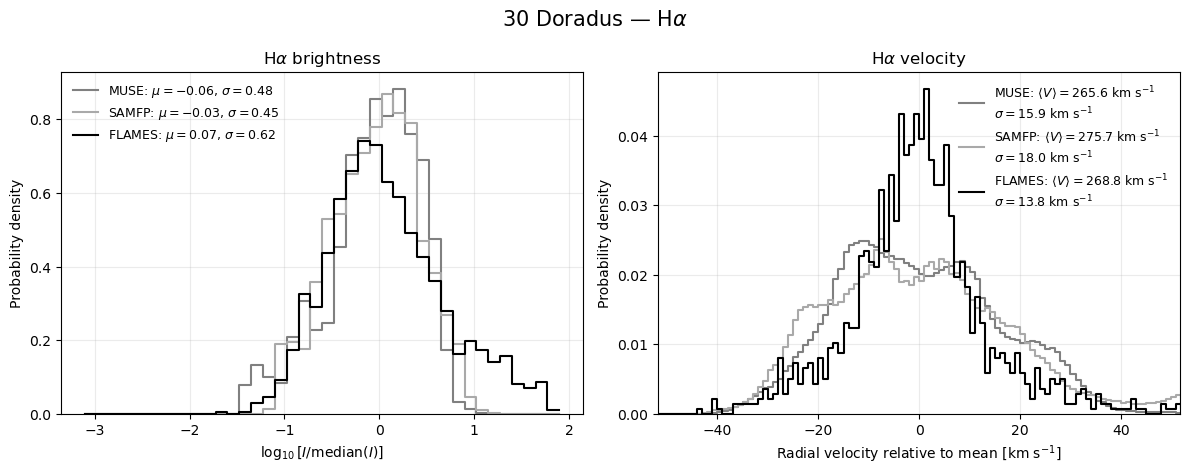

In [36]:
# --------------------------------------------------
# Linear-density version
# --------------------------------------------------

plot_velocity_brightness_distributions(
    processed_data,
    velocity_binwidth=1.0,
    brightness_bins=40,
    log_y=False,
    savepath=(
        FIGS_DIR
        / "velocity_brightness_distributions.pdf"
    ),
)


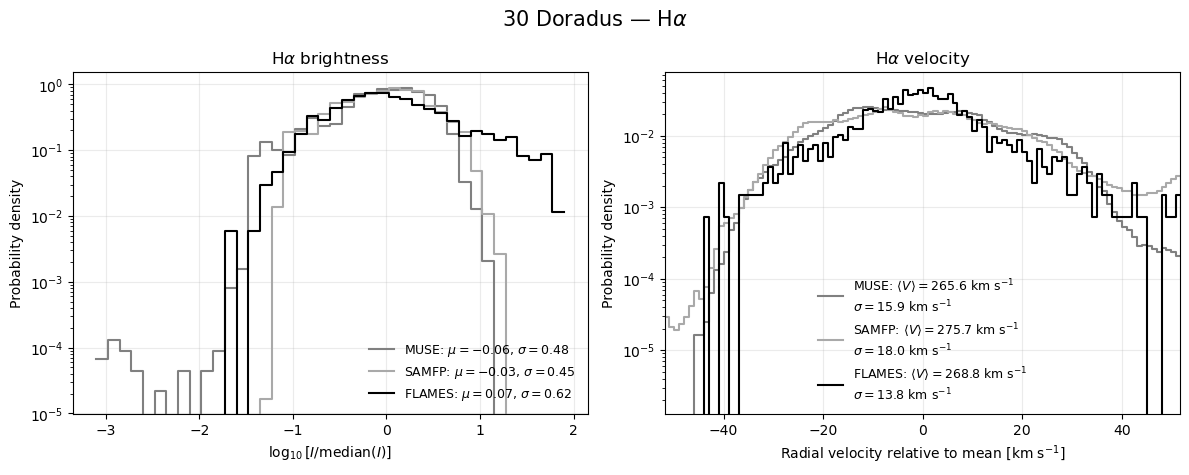

In [37]:
# --------------------------------------------------
# Optional log-density version
# --------------------------------------------------

plot_velocity_brightness_distributions(
    processed_data,
    velocity_binwidth=1.0,
    brightness_bins=40,
    log_y=True,
    savepath=(
        FIGS_DIR
        / "velocity_brightness_distributions_log.pdf"
    ),
)


## Optional: native brightness PDFs

Use the following function only after confirming compatible intensity definitions, physical units, and calibration. FLAMES `10**log_F` is the upstream brightness quantity; the supplied files do not establish that it is integrated flux or surface brightness. The default normalized plots above do not require a shared multiplicative calibration.


In [34]:
def plot_absolute_brightness_pdf(
    data,
    instrument_order=("MUSE", "SAMFP"),
    bins=40,
    xlim=None,
    log_y=False,
    savepath=None,
):
    fig, ax = plt.subplots(figsize=(7, 5))

    for instrument in instrument_order:
        inst_df = data[data["instrument"] == instrument]

        if inst_df.empty:
            continue

        sns.histplot(
            data=inst_df,
            x="log_SB",
            bins=bins,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(instrument),
            label=instrument,
            ax=ax,
        )

    if xlim is not None:
        ax.set_xlim(*xlim)

    if log_y:
        ax.set_yscale("log")

    ax.set_xlabel(r"$\log_{10}(I)$")
    ax.set_ylabel("Probability density")
    ax.set_title(r"30 Doradus — H$\alpha$ brightness PDF")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(
            savepath,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
